In [3]:
import pandas as pd
import numpy as np

# Load training data
train = pd.read_csv("/content/train_aWnotuB.csv")

print("Dataset Shape:", train.shape)

print("\nColumn Names:")
print(train.columns.tolist())

print("\nData Types:")
print(train.dtypes)

print("\nFirst 10 Rows:")
display(train.head(10))

print("\nMissing Values:")
print(train.isnull().sum())

print("\nDuplicate Rows:")
print(train.duplicated().sum())

print("\nBasic Statistics:")
display(train.describe())

Dataset Shape: (48120, 4)

Column Names:
['DateTime', 'Junction', 'Vehicles', 'ID']

Data Types:
DateTime    object
Junction     int64
Vehicles     int64
ID           int64
dtype: object

First 10 Rows:


,DateTime,Junction,Vehicles,ID
0,2015-11-01 00:00:00,1,15,20151101001
1,2015-11-01 01:00:00,1,13,20151101011
2,2015-11-01 02:00:00,1,10,20151101021
3,2015-11-01 03:00:00,1,7,20151101031
4,2015-11-01 04:00:00,1,9,20151101041
5,2015-11-01 05:00:00,1,6,20151101051
6,2015-11-01 06:00:00,1,9,20151101061
7,2015-11-01 07:00:00,1,8,20151101071
8,2015-11-01 08:00:00,1,11,20151101081
9,2015-11-01 09:00:00,1,12,20151101091



Missing Values:
DateTime    0
Junction    0
Vehicles    0
ID          0
dtype: int64

Duplicate Rows:
0

Basic Statistics:


,Junction,Vehicles,ID
count,48120.000000,48120.000000,4.812000e+04
mean,2.180549,22.791334,2.016330e+10
std,0.966955,20.750063,5.944854e+06
min,1.000000,1.000000,2.015110e+10
25%,1.000000,9.000000,2.016042e+10
50%,2.000000,15.000000,2.016093e+10
75%,3.000000,29.000000,2.017023e+10
max,4.000000,180.000000,2.017063e+10


In [4]:
print("Junctions:")
print(sorted(train["Junction"].unique()))

print("\nNumber of observations per junction:")
print(train["Junction"].value_counts().sort_index())

print("\nDate range:")
print("Start:", train["DateTime"].min())
print("End:", train["DateTime"].max())

Junctions:
[np.int64(1), np.int64(2), np.int64(3), np.int64(4)]

Number of observations per junction:
Junction
1    14592
2    14592
3    14592
4     4344
Name: count, dtype: int64

Date range:
Start: 2015-11-01 00:00:00
End: 2017-06-30 23:00:00


In [5]:
train["DateTime"] = pd.to_datetime(train["DateTime"])

print(train.dtypes)

print("\nDate range:")
print("Start:", train["DateTime"].min())
print("End:", train["DateTime"].max())

DateTime    datetime64[ns]
Junction             int64
Vehicles             int64
ID                   int64
dtype: object

Date range:
Start: 2015-11-01 00:00:00
End: 2017-06-30 23:00:00


In [6]:
train["Hour"] = train["DateTime"].dt.hour
train["Day"] = train["DateTime"].dt.day
train["Month"] = train["DateTime"].dt.month
train["DayOfWeek"] = train["DateTime"].dt.dayofweek

train["IsWeekend"] = train["DayOfWeek"].isin([5, 6])

display(train.head())

,DateTime,Junction,Vehicles,ID,Hour,Day,Month,DayOfWeek,IsWeekend
0,2015-11-01 00:00:00,1,15,20151101001,0,1,11,6,True
1,2015-11-01 01:00:00,1,13,20151101011,1,1,11,6,True
2,2015-11-01 02:00:00,1,10,20151101021,2,1,11,6,True
3,2015-11-01 03:00:00,1,7,20151101031,3,1,11,6,True
4,2015-11-01 04:00:00,1,9,20151101041,4,1,11,6,True


In [7]:
# Convert DateTime to proper datetime format
train["DateTime"] = pd.to_datetime(train["DateTime"])

# Create useful time-based features
train["Hour"] = train["DateTime"].dt.hour
train["Day"] = train["DateTime"].dt.day
train["DayOfWeek"] = train["DateTime"].dt.dayofweek
train["Month"] = train["DateTime"].dt.month
train["Year"] = train["DateTime"].dt.year
train["IsWeekend"] = train["DayOfWeek"] >= 5

# Display the result
display(train.head(10))

,DateTime,Junction,Vehicles,ID,Hour,Day,Month,DayOfWeek,IsWeekend,Year
0,2015-11-01 00:00:00,1,15,20151101001,0,1,11,6,True,2015
1,2015-11-01 01:00:00,1,13,20151101011,1,1,11,6,True,2015
2,2015-11-01 02:00:00,1,10,20151101021,2,1,11,6,True,2015
3,2015-11-01 03:00:00,1,7,20151101031,3,1,11,6,True,2015
4,2015-11-01 04:00:00,1,9,20151101041,4,1,11,6,True,2015
5,2015-11-01 05:00:00,1,6,20151101051,5,1,11,6,True,2015
6,2015-11-01 06:00:00,1,9,20151101061,6,1,11,6,True,2015
7,2015-11-01 07:00:00,1,8,20151101071,7,1,11,6,True,2015
8,2015-11-01 08:00:00,1,11,20151101081,8,1,11,6,True,2015
9,2015-11-01 09:00:00,1,12,20151101091,9,1,11,6,True,2015


In [8]:
# Average traffic for each hour
hourly_traffic = train.groupby("Hour")["Vehicles"].mean()

print("Average Vehicles by Hour:")
display(hourly_traffic)

Average Vehicles by Hour:


,Vehicles
Hour,
0,23.540648
1,19.654863
2,17.102743
3,14.847382
4,12.973067
5,12.173566
6,12.980050
7,14.703242
8,16.402993


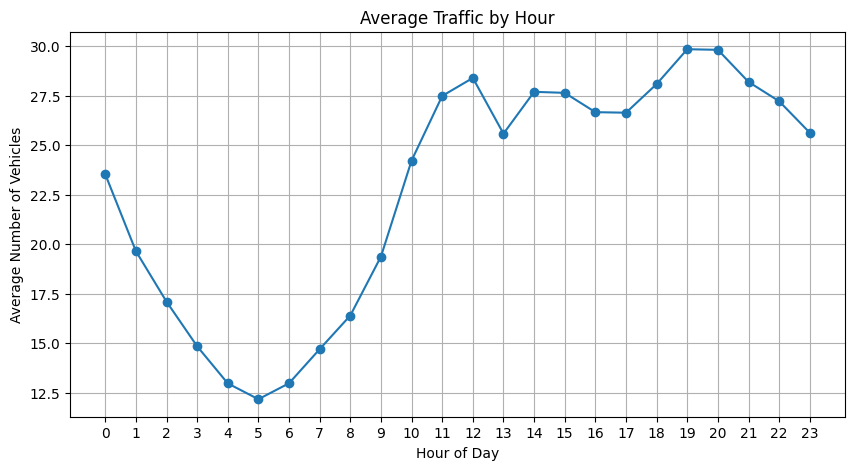

In [9]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(hourly_traffic.index, hourly_traffic.values, marker="o")

plt.title("Average Traffic by Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Average Number of Vehicles")
plt.xticks(range(24))
plt.grid(True)

plt.show()

In [10]:
# Average traffic at each junction
junction_traffic = train.groupby("Junction")["Vehicles"].mean()

print("Average Vehicles by Junction:")
display(junction_traffic)

Average Vehicles by Junction:


,Vehicles
Junction,
1,45.052906
2,14.253221
3,13.694010
4,7.251611


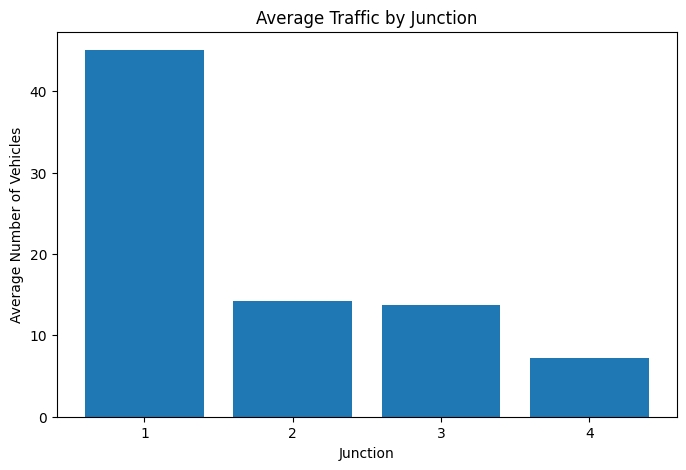

In [11]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.bar(junction_traffic.index.astype(str), junction_traffic.values)

plt.title("Average Traffic by Junction")
plt.xlabel("Junction")
plt.ylabel("Average Number of Vehicles")

plt.show()

In [12]:
# Average traffic on weekdays vs weekends
weekend_traffic = train.groupby("IsWeekend")["Vehicles"].mean()

print("Average Traffic: Weekday vs Weekend")
display(weekend_traffic)

Average Traffic: Weekday vs Weekend


,Vehicles
IsWeekend,
False,24.760163
True,17.834722


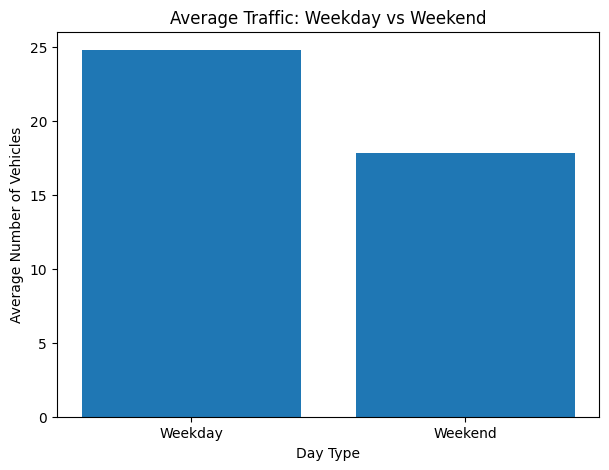

In [13]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 5))

plt.bar(
    ["Weekday", "Weekend"],
    weekend_traffic.values
)

plt.title("Average Traffic: Weekday vs Weekend")
plt.xlabel("Day Type")
plt.ylabel("Average Number of Vehicles")

plt.show()

In [14]:
# Average traffic by day of the week
daily_traffic = train.groupby("DayOfWeek")["Vehicles"].mean()

# Give days readable names
day_names = {
    0: "Monday",
    1: "Tuesday",
    2: "Wednesday",
    3: "Thursday",
    4: "Friday",
    5: "Saturday",
    6: "Sunday"
}

daily_traffic.index = daily_traffic.index.map(day_names)

print("Average Traffic by Day of Week:")
display(daily_traffic)

Average Traffic by Day of Week:


,Vehicles
DayOfWeek,
Monday,24.409408
Tuesday,25.286731
Wednesday,25.149681
Thursday,25.152875
Friday,23.802120
Saturday,18.544611
Sunday,17.134727


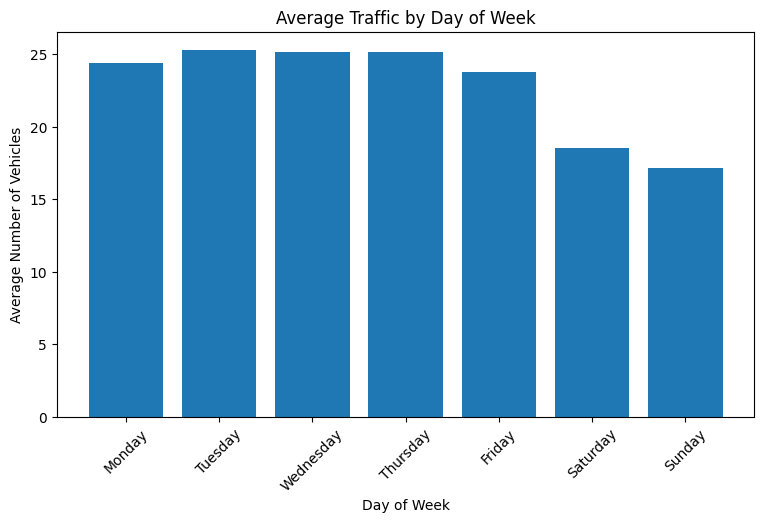

In [15]:
plt.figure(figsize=(9, 5))

plt.bar(daily_traffic.index, daily_traffic.values)

plt.title("Average Traffic by Day of Week")
plt.xlabel("Day of Week")
plt.ylabel("Average Number of Vehicles")

plt.xticks(rotation=45)
plt.show()

In [16]:
# Average traffic by junction and hour
junction_hour_traffic = train.groupby(
    ["Junction", "Hour"]
)["Vehicles"].mean().unstack()

display(junction_hour_traffic)

Hour,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
Junction,,,,,,,,,,,,,,,,,,,,,
1,45.738487,39.156250,33.907895,29.430921,25.654605,24.067434,26.080592,29.526316,32.735197,39.003289,...,54.733553,54.218750,51.911184,51.851974,55.411184,58.804276,57.401316,54.537829,52.963816,50.088816
2,15.656250,14.115132,12.995066,11.468750,10.000000,9.217105,9.263158,10.064145,10.745066,11.611842,...,16.307566,16.796053,16.493421,16.427632,16.782895,17.883224,18.060855,17.236842,16.819079,16.174342
3,14.174342,9.856908,8.055921,6.776316,5.978618,5.685855,6.236842,7.550987,9.057566,11.429276,...,17.572368,17.371711,16.881579,16.901316,17.929276,19.129934,20.200658,18.722039,17.394737,15.800987
4,6.922652,5.668508,4.839779,4.320442,3.856354,3.944751,4.110497,4.519337,5.220994,6.259669,...,9.209945,9.392265,8.994475,9.060773,8.486188,8.850829,9.038674,8.425414,8.762431,8.309392


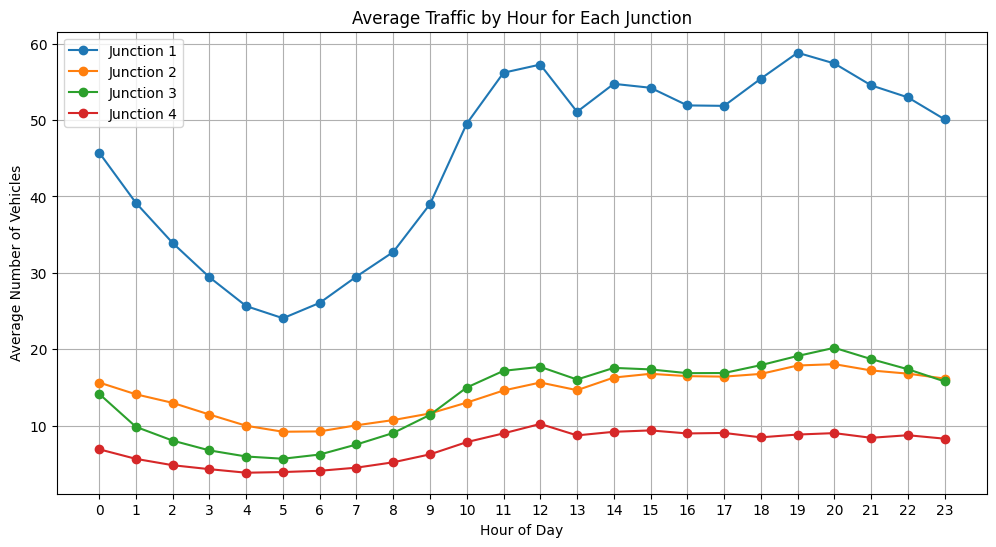

In [17]:
plt.figure(figsize=(12, 6))

for junction in junction_hour_traffic.index:
    plt.plot(
        junction_hour_traffic.columns,
        junction_hour_traffic.loc[junction],
        marker="o",
        label=f"Junction {junction}"
    )

plt.title("Average Traffic by Hour for Each Junction")
plt.xlabel("Hour of Day")
plt.ylabel("Average Number of Vehicles")
plt.xticks(range(24))
plt.legend()
plt.grid(True)

plt.show()

In [18]:
# Average traffic by month
monthly_traffic = train.groupby(
    ["Year", "Month"]
)["Vehicles"].mean()

print("Average Traffic by Year and Month:")
display(monthly_traffic)

Average Traffic by Year and Month:


Year  Month
2015  11       11.911574
      12       11.121416
2016  1        13.799731
      2        17.524425
      3        17.512993
      4        19.358333
      5        19.552419
      6        18.889815
      7        21.837814
      8        21.936380
      9        25.644907
      10       26.551075
      11       27.156944
      12       26.806452
2017  1        24.173051
      2        27.186384
      3        27.243616
      4        28.276389
      5        28.444220
      6        31.388889
Name: Vehicles, dtype: float64

In [19]:
# Check the current Project 9 dataset
print("Dataset Shape:", train.shape)

print("\nColumns:")
print(train.columns.tolist())

print("\nFirst 5 rows:")
display(train.head())

Dataset Shape: (48120, 10)

Columns:
['DateTime', 'Junction', 'Vehicles', 'ID', 'Hour', 'Day', 'Month', 'DayOfWeek', 'IsWeekend', 'Year']

First 5 rows:


,DateTime,Junction,Vehicles,ID,Hour,Day,Month,DayOfWeek,IsWeekend,Year
0,2015-11-01 00:00:00,1,15,20151101001,0,1,11,6,True,2015
1,2015-11-01 01:00:00,1,13,20151101011,1,1,11,6,True,2015
2,2015-11-01 02:00:00,1,10,20151101021,2,1,11,6,True,2015
3,2015-11-01 03:00:00,1,7,20151101031,3,1,11,6,True,2015
4,2015-11-01 04:00:00,1,9,20151101041,4,1,11,6,True,2015


In [20]:
# Sort data chronologically
train = train.sort_values('DateTime').reset_index(drop=True)

# Use the first 80% for training and the last 20% for validation
split_index = int(len(train) * 0.8)

train_data = train.iloc[:split_index].copy()
val_data = train.iloc[split_index:].copy()

print("Training data shape:", train_data.shape)
print("Validation data shape:", val_data.shape)

print("\nTraining period:")
print(train_data['DateTime'].min(), "to", train_data['DateTime'].max())

print("\nValidation period:")
print(val_data['DateTime'].min(), "to", val_data['DateTime'].max())

Training data shape: (38496, 10)
Validation data shape: (9624, 10)

Training period:
2015-11-01 00:00:00 to 2017-03-22 17:00:00

Validation period:
2017-03-22 18:00:00 to 2017-06-30 23:00:00


In [21]:
# Features for the baseline model
features = [
    'Junction',
    'Hour',
    'Day',
    'Month',
    'DayOfWeek',
    'IsWeekend',
    'Year'
]

target = 'Vehicles'

X_train = train_data[features]
y_train = train_data[target]

X_val = val_data[features]
y_val = val_data[target]

print("X_train shape:", X_train.shape)
print("X_val shape:", X_val.shape)
print("y_train shape:", y_train.shape)
print("y_val shape:", y_val.shape)

X_train shape: (38496, 7)
X_val shape: (9624, 7)
y_train shape: (38496,)
y_val shape: (9624,)


In [22]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Create the Random Forest model
rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

# Train the model
rf_model.fit(X_train, y_train)

# Make predictions
y_pred = rf_model.predict(X_val)

# Evaluate the model
mae = mean_absolute_error(y_val, y_pred)
rmse = np.sqrt(mean_squared_error(y_val, y_pred))
r2 = r2_score(y_val, y_pred)

print("Baseline Random Forest Results")
print("--------------------------------")
print("MAE :", round(mae, 4))
print("RMSE:", round(rmse, 4))
print("R²  :", round(r2, 4))

Baseline Random Forest Results
--------------------------------
MAE : 5.352
RMSE: 9.2945
R²  : 0.8834


In [23]:
# Get feature importance
importance = pd.DataFrame({
    'Feature': features,
    'Importance': rf_model.feature_importances_
})

importance = importance.sort_values(
    by='Importance',
    ascending=False
)

print("Feature Importance:")
display(importance)

Feature Importance:


,Feature,Importance
0,Junction,0.520463
1,Hour,0.148038
6,Year,0.127658
3,Month,0.087800
4,DayOfWeek,0.046041
2,Day,0.042242
5,IsWeekend,0.027758


In [24]:
# Create a copy of the complete dataset
traffic_model = train.sort_values(
    ['Junction', 'DateTime']
).copy()

# Create lag features separately for each junction
traffic_model['Lag_1'] = (
    traffic_model.groupby('Junction')['Vehicles'].shift(1)
)

traffic_model['Lag_2'] = (
    traffic_model.groupby('Junction')['Vehicles'].shift(2)
)

# Rolling mean of previous 3 observations
traffic_model['Rolling_Mean_3'] = (
    traffic_model.groupby('Junction')['Vehicles']
    .shift(1)
    .rolling(3)
    .mean()
    .reset_index(level=0, drop=True)
)

# Remove rows where lag/rolling values are unavailable
traffic_model = traffic_model.dropna(
    subset=['Lag_1', 'Lag_2', 'Rolling_Mean_3']
).copy()

print("Dataset shape after lag features:", traffic_model.shape)

display(
    traffic_model[
        ['DateTime', 'Junction', 'Vehicles',
         'Lag_1', 'Lag_2', 'Rolling_Mean_3']
    ].head(10)
)

Dataset shape after lag features: (48103, 13)


,DateTime,Junction,Vehicles,Lag_1,Lag_2,Rolling_Mean_3
7,2015-11-01 02:00:00,1,10,13.0,15.0,8.000000
11,2015-11-01 03:00:00,1,7,10.0,13.0,12.666667
14,2015-11-01 04:00:00,1,9,7.0,10.0,16.000000
16,2015-11-01 05:00:00,1,6,9.0,7.0,14.333333
19,2015-11-01 06:00:00,1,9,6.0,9.0,15.000000
21,2015-11-01 07:00:00,1,8,9.0,6.0,18.000000
25,2015-11-01 08:00:00,1,11,8.0,9.0,16.333333
28,2015-11-01 09:00:00,1,12,11.0,8.0,12.666667
30,2015-11-01 10:00:00,1,15,12.0,11.0,11.666667
35,2015-11-01 11:00:00,1,17,15.0,12.0,22.000000


In [25]:
# Recalculate Rolling_Mean_3 correctly for each junction
traffic_model = train.sort_values(
    ['Junction', 'DateTime']
).copy()

# Lag features
traffic_model['Lag_1'] = (
    traffic_model.groupby('Junction')['Vehicles'].shift(1)
)

traffic_model['Lag_2'] = (
    traffic_model.groupby('Junction')['Vehicles'].shift(2)
)

# Mean of the previous 3 observations only
traffic_model['Rolling_Mean_3'] = (
    traffic_model.groupby('Junction')['Vehicles']
    .transform(lambda x: x.shift(1).rolling(window=3).mean())
)

# Remove rows without complete lag/rolling values
traffic_model = traffic_model.dropna(
    subset=['Lag_1', 'Lag_2', 'Rolling_Mean_3']
).copy()

print("Dataset shape:", traffic_model.shape)

display(
    traffic_model[
        ['DateTime', 'Junction', 'Vehicles',
         'Lag_1', 'Lag_2', 'Rolling_Mean_3']
    ].head(10)
)

Dataset shape: (48108, 13)


,DateTime,Junction,Vehicles,Lag_1,Lag_2,Rolling_Mean_3
11,2015-11-01 03:00:00,1,7,10.0,13.0,12.666667
14,2015-11-01 04:00:00,1,9,7.0,10.0,10.000000
16,2015-11-01 05:00:00,1,6,9.0,7.0,8.666667
19,2015-11-01 06:00:00,1,9,6.0,9.0,7.333333
21,2015-11-01 07:00:00,1,8,9.0,6.0,8.000000
25,2015-11-01 08:00:00,1,11,8.0,9.0,7.666667
28,2015-11-01 09:00:00,1,12,11.0,8.0,9.333333
30,2015-11-01 10:00:00,1,15,12.0,11.0,10.333333
35,2015-11-01 11:00:00,1,17,15.0,12.0,12.666667
38,2015-11-01 12:00:00,1,16,17.0,15.0,14.666667


In [26]:
# Sort chronologically
traffic_model = traffic_model.sort_values('DateTime').reset_index(drop=True)

# 80% training, 20% validation
split_index = int(len(traffic_model) * 0.8)

model_train = traffic_model.iloc[:split_index].copy()
model_val = traffic_model.iloc[split_index:].copy()

print("Improved model training shape:", model_train.shape)
print("Improved model validation shape:", model_val.shape)

print("\nTraining period:")
print(model_train['DateTime'].min(), "to", model_train['DateTime'].max())

print("\nValidation period:")
print(model_val['DateTime'].min(), "to", model_val['DateTime'].max())

Improved model training shape: (38486, 13)
Improved model validation shape: (9622, 13)

Training period:
2015-11-01 03:00:00 to 2017-03-22 18:00:00

Validation period:
2017-03-22 18:00:00 to 2017-06-30 23:00:00


In [27]:
# Features including historical traffic information
improved_features = [
    'Junction',
    'Hour',
    'Day',
    'Month',
    'DayOfWeek',
    'IsWeekend',
    'Year',
    'Lag_1',
    'Lag_2',
    'Rolling_Mean_3'
]

X_train_imp = model_train[improved_features]
y_train_imp = model_train['Vehicles']

X_val_imp = model_val[improved_features]
y_val_imp = model_val['Vehicles']

print("X_train shape:", X_train_imp.shape)
print("X_val shape:", X_val_imp.shape)
print("y_train shape:", y_train_imp.shape)
print("y_val shape:", y_val_imp.shape)

X_train shape: (38486, 10)
X_val shape: (9622, 10)
y_train shape: (38486,)
y_val shape: (9622,)


In [28]:
# Improved Random Forest with lag features
rf_improved = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

# Train
rf_improved.fit(X_train_imp, y_train_imp)

# Predict
y_pred_imp = rf_improved.predict(X_val_imp)

# Evaluate
mae_imp = mean_absolute_error(y_val_imp, y_pred_imp)
rmse_imp = np.sqrt(mean_squared_error(y_val_imp, y_pred_imp))
r2_imp = r2_score(y_val_imp, y_pred_imp)

print("Improved Random Forest Results")
print("--------------------------------")
print("MAE :", round(mae_imp, 4))
print("RMSE:", round(rmse_imp, 4))
print("R²  :", round(r2_imp, 4))

Improved Random Forest Results
--------------------------------
MAE : 3.1206
RMSE: 5.0047
R²  : 0.9662


In [29]:
# Compare baseline and improved models

comparison = pd.DataFrame({
    "Model": ["Baseline Random Forest", "Improved Random Forest"],
    "MAE": [mae, mae_imp],
    "RMSE": [rmse, rmse_imp],
    "R2": [r2, r2_imp]
})

display(comparison.round(4))

,Model,MAE,RMSE,R2
0,Baseline Random Forest,5.3520,9.2945,0.8834
1,Improved Random Forest,3.1206,5.0047,0.9662


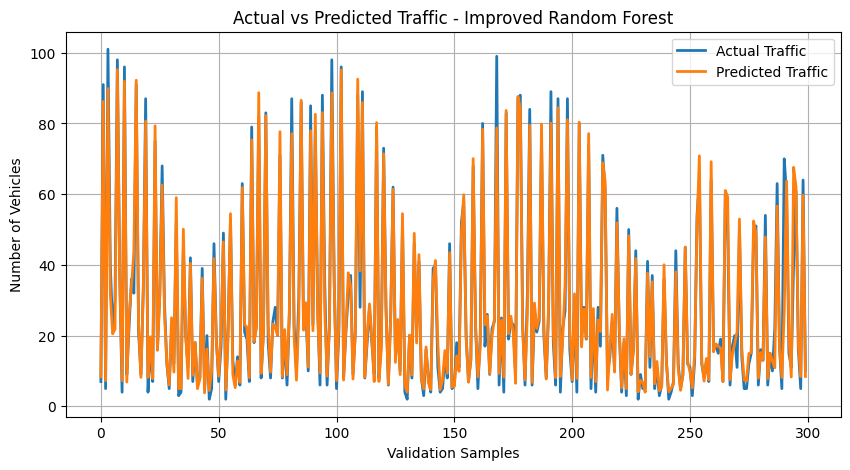

In [30]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(
    y_val_imp.values[:300],
    label="Actual Traffic",
    linewidth=2
)

plt.plot(
    y_pred_imp[:300],
    label="Predicted Traffic",
    linewidth=2
)

plt.xlabel("Validation Samples")
plt.ylabel("Number of Vehicles")
plt.title("Actual vs Predicted Traffic - Improved Random Forest")
plt.legend()
plt.grid(True)
plt.show()

In [31]:
# Week 3 - Project 9: Residual Analysis

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Actual and predicted traffic
actual = np.asarray(y_val_imp)
predicted = np.asarray(y_pred_imp)

# Calculate prediction errors
residuals = actual - predicted

# Summary of prediction errors
print("Residual Analysis")
print("-----------------")
print("Mean Residual:", round(np.mean(residuals), 4))
print("Mean Absolute Error:", round(np.mean(np.abs(residuals)), 4))
print("Maximum Absolute Error:",
      round(np.max(np.abs(residuals)), 4))
print("Minimum Residual:", round(np.min(residuals), 4))
print("Maximum Residual:", round(np.max(residuals), 4))

Residual Analysis
-----------------
Mean Residual: 0.4259
Mean Absolute Error: 3.1206
Maximum Absolute Error: 134.42
Minimum Residual: -54.86
Maximum Residual: 134.42


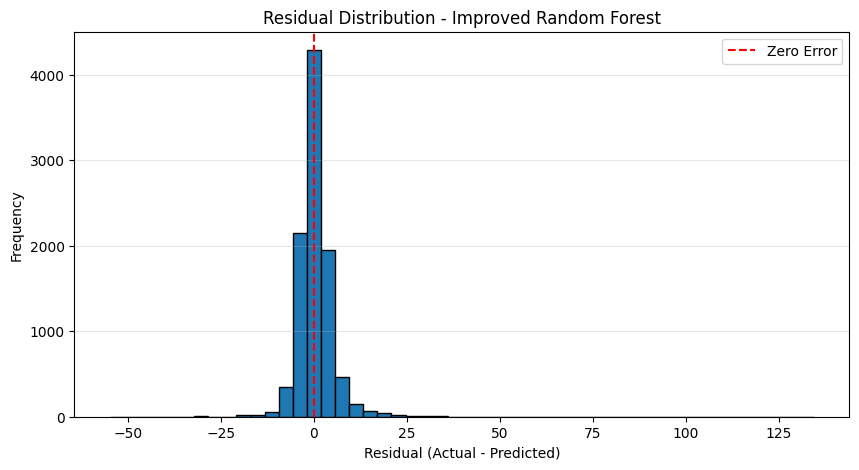

In [32]:
# Week 3 - Project 9: Residual Visualization

plt.figure(figsize=(10, 5))

plt.hist(residuals, bins=50, edgecolor='black')

plt.axvline(
    0,
    color='red',
    linestyle='--',
    label='Zero Error'
)

plt.xlabel("Residual (Actual - Predicted)")
plt.ylabel("Frequency")
plt.title("Residual Distribution - Improved Random Forest")
plt.legend()
plt.grid(axis='y', alpha=0.3)
plt.show()

In [33]:
print("Actual length:", len(actual))
print("Predicted length:", len(predicted))
print("Residual length:", len(residuals))

print("val_data shape:", val_data.shape)
print("model_val shape:", model_val.shape)
print("traffic_model shape:", traffic_model.shape)

Actual length: 9622
Predicted length: 9622
Residual length: 9622
val_data shape: (9624, 10)
model_val shape: (9622, 13)
traffic_model shape: (48108, 13)


In [34]:
# Week 3 - Project 9: Largest prediction errors

error_analysis = pd.DataFrame({
    'DateTime': model_val['DateTime'].to_numpy(),
    'Junction': model_val['Junction'].to_numpy(),
    'Actual': actual,
    'Predicted': predicted,
    'Residual': residuals,
    'Absolute_Error': np.abs(residuals)
})

largest_errors = error_analysis.sort_values(
    'Absolute_Error',
    ascending=False
).head(10)

display(largest_errors.round(3))

,DateTime,Junction,Actual,Predicted,Residual,Absolute_Error
8815,2017-06-22 14:00:00,3,162,27.58,134.42,134.42
7967,2017-06-13 18:00:00,3,112,23.47,88.53,88.53
7970,2017-06-13 19:00:00,3,69,123.86,-54.86,54.86
8821,2017-06-22 15:00:00,3,83,130.25,-47.25,47.25
7573,2017-06-09 15:00:00,3,64,19.82,44.18,44.18
6641,2017-05-30 22:00:00,1,48,92.03,-44.03,44.03
290,2017-03-25 19:00:00,3,70,26.69,43.31,43.31
5826,2017-05-22 11:00:00,1,136,99.63,36.37,36.37
9283,2017-06-27 11:00:00,1,128,91.90,36.10,36.10
6115,2017-05-25 11:00:00,1,128,92.21,35.79,35.79


In [35]:
# Week 3 - Project 9: Performance by Junction

junction_results = []

for junction in sorted(error_analysis['Junction'].unique()):
    data = error_analysis[
        error_analysis['Junction'] == junction
    ]

    junction_results.append({
        'Junction': junction,
        'Observations': len(data),
        'MAE': mean_absolute_error(
            data['Actual'], data['Predicted']
        ),
        'RMSE': np.sqrt(mean_squared_error(
            data['Actual'], data['Predicted']
        )),
        'R2': r2_score(
            data['Actual'], data['Predicted']
        )
    })

junction_metrics = pd.DataFrame(junction_results)

display(junction_metrics.round(4))

,Junction,Observations,MAE,RMSE,R2
0,1,2406,4.5560,6.4880,0.9290
1,2,2405,2.7230,3.6508,0.8163
2,3,2405,3.2087,6.1143,0.6826
3,4,2406,1.9948,2.7167,0.4271


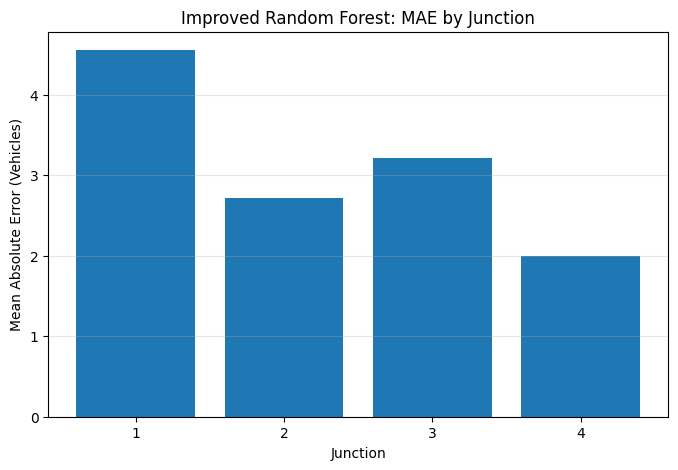

In [36]:
# Week 3 - Project 9: MAE by Junction

plt.figure(figsize=(8, 5))

plt.bar(
    junction_metrics['Junction'].astype(str),
    junction_metrics['MAE']
)

plt.xlabel("Junction")
plt.ylabel("Mean Absolute Error (Vehicles)")
plt.title("Improved Random Forest: MAE by Junction")
plt.grid(axis='y', alpha=0.3)
plt.show()

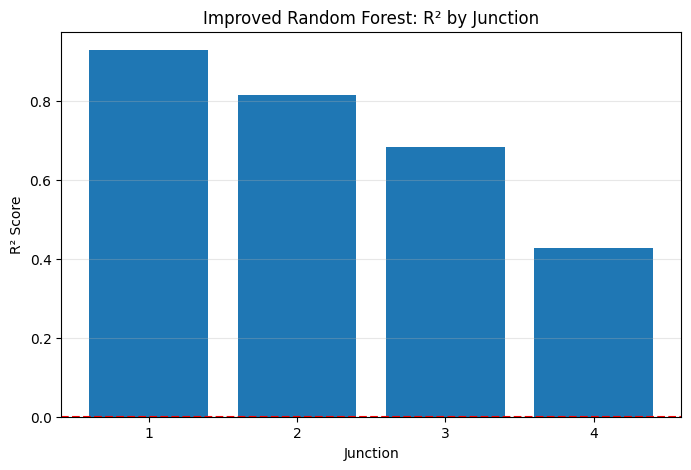

In [37]:
# Week 3 - Project 9: R² by Junction

plt.figure(figsize=(8, 5))

plt.bar(
    junction_metrics['Junction'].astype(str),
    junction_metrics['R2']
)

plt.axhline(
    0,
    color='red',
    linestyle='--'
)

plt.xlabel("Junction")
plt.ylabel("R² Score")
plt.title("Improved Random Forest: R² by Junction")
plt.grid(axis='y', alpha=0.3)
plt.show()

In [38]:
# Week 3 - Project 9: Mean residual by junction

residual_by_junction = (
    error_analysis
    .groupby('Junction')
    .agg(
        Mean_Residual=('Residual', 'mean'),
        Mean_Absolute_Error=('Absolute_Error', 'mean'),
        Maximum_Absolute_Error=('Absolute_Error', 'max')
    )
    .reset_index()
)

display(residual_by_junction.round(4))

,Junction,Mean_Residual,Mean_Absolute_Error,Maximum_Absolute_Error
0,1,2.0599,4.5560,44.03
1,2,0.1813,2.7230,20.29
2,3,0.2024,3.2087,134.42
3,4,-0.7403,1.9948,27.48


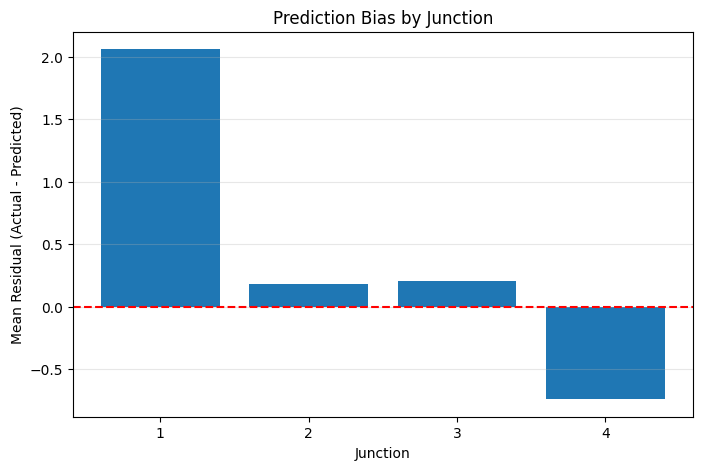

In [39]:
# Week 3 - Project 9: Residual Bias by Junction

plt.figure(figsize=(8, 5))

plt.bar(
    residual_by_junction['Junction'].astype(str),
    residual_by_junction['Mean_Residual']
)

plt.axhline(0, color='red', linestyle='--')

plt.xlabel("Junction")
plt.ylabel("Mean Residual (Actual - Predicted)")
plt.title("Prediction Bias by Junction")
plt.grid(axis='y', alpha=0.3)
plt.show()

In [40]:
# Week 4 - Project 9: Check available datasets and models

variables_to_check = [
    "train",
    "test",
    "traffic_model",
    "model_train",
    "model_val",
    "X_train_imp",
    "X_val_imp",
    "rf_improved",
    "y_pred_imp"
]

for name in variables_to_check:
    if name in globals():
        obj = globals()[name]

        if hasattr(obj, "shape"):
            print(name, "->", obj.shape)
        else:
            print(name, "-> Available")
    else:
        print(name, "-> Not available")

train -> (48120, 10)
test -> Not available
traffic_model -> (48108, 13)
model_train -> (38486, 13)
model_val -> (9622, 13)
X_train_imp -> (38486, 10)
X_val_imp -> (9622, 10)
rf_improved -> Available
y_pred_imp -> (9622,)


In [41]:
import pandas as pd

# Load the existing test CSV file
test = pd.read_csv(
    "/content/datasets_8494_11879_test_BdBKkAj.csv"
)

print("Test Dataset Shape:", test.shape)

print("\nColumns:")
print(test.columns.tolist())

print("\nFirst 5 rows:")
display(test.head())

Test Dataset Shape: (11808, 3)

Columns:
['DateTime', 'Junction', 'ID']

First 5 rows:


,DateTime,Junction,ID
0,2017-07-01 00:00:00,1,20170701001
1,2017-07-01 01:00:00,1,20170701011
2,2017-07-01 02:00:00,1,20170701021
3,2017-07-01 03:00:00,1,20170701031
4,2017-07-01 04:00:00,1,20170701041


In [42]:
# Check features used during model training

print("Traffic Model Columns:")
print(traffic_model.columns.tolist())

print("\nTraining Feature Columns:")
print(X_train_imp.columns.tolist())

print("\nModel Expected Features:")
print(rf_improved.feature_names_in_)

Traffic Model Columns:
['DateTime', 'Junction', 'Vehicles', 'ID', 'Hour', 'Day', 'Month', 'DayOfWeek', 'IsWeekend', 'Year', 'Lag_1', 'Lag_2', 'Rolling_Mean_3']

Training Feature Columns:
['Junction', 'Hour', 'Day', 'Month', 'DayOfWeek', 'IsWeekend', 'Year', 'Lag_1', 'Lag_2', 'Rolling_Mean_3']

Model Expected Features:
['Junction' 'Hour' 'Day' 'Month' 'DayOfWeek' 'IsWeekend' 'Year' 'Lag_1'
 'Lag_2' 'Rolling_Mean_3']


In [43]:
# Inspect lag features for Junction 1

junction_data = (
    traffic_model[traffic_model['Junction'] == 1]
    .sort_values('DateTime')
)

display(
    junction_data[
        ['DateTime', 'Vehicles',
         'Lag_1', 'Lag_2', 'Rolling_Mean_3']
    ].head(10)
)

,DateTime,Vehicles,Lag_1,Lag_2,Rolling_Mean_3
0,2015-11-01 03:00:00,7,10.0,13.0,12.666667
4,2015-11-01 04:00:00,9,7.0,10.0,10.000000
7,2015-11-01 05:00:00,6,9.0,7.0,8.666667
11,2015-11-01 06:00:00,9,6.0,9.0,7.333333
14,2015-11-01 07:00:00,8,9.0,6.0,8.000000
16,2015-11-01 08:00:00,11,8.0,9.0,7.666667
19,2015-11-01 09:00:00,12,11.0,8.0,9.333333
21,2015-11-01 10:00:00,15,12.0,11.0,10.333333
25,2015-11-01 11:00:00,17,15.0,12.0,12.666667
28,2015-11-01 12:00:00,16,17.0,15.0,14.666667


In [45]:
# Week 4 - Project 9: Get historical traffic values

train['DateTime'] = pd.to_datetime(train['DateTime'])
test['DateTime'] = pd.to_datetime(test['DateTime'])

# Sort training data
train_sorted = train.sort_values(
    ['Junction', 'DateTime']
).copy()

# Display last 3 observations for each junction
for junction in sorted(train_sorted['Junction'].unique()):

    print(f"\nJunction {junction} - Last 3 observations:")

    display(
        train_sorted[
            train_sorted['Junction'] == junction
        ][['DateTime', 'Vehicles']]
        .tail(3)
    )


Junction 1 - Last 3 observations:


,DateTime,Vehicles
48108,2017-06-30 21:00:00,90
48114,2017-06-30 22:00:00,84
48116,2017-06-30 23:00:00,78



Junction 2 - Last 3 observations:


,DateTime,Vehicles
48111,2017-06-30 21:00:00,31
48112,2017-06-30 22:00:00,29
48118,2017-06-30 23:00:00,27



Junction 3 - Last 3 observations:


,DateTime,Vehicles
48110,2017-06-30 21:00:00,28
48115,2017-06-30 22:00:00,26
48117,2017-06-30 23:00:00,39



Junction 4 - Last 3 observations:


,DateTime,Vehicles
48109,2017-06-30 21:00:00,16
48113,2017-06-30 22:00:00,22
48119,2017-06-30 23:00:00,12


In [46]:
# Week 4 - Project 9: Recursive Traffic Prediction

from collections import deque

# Sort test data chronologically
test_sorted = test.sort_values(
    ['DateTime', 'Junction']
).copy()

# Store historical traffic values for each junction
history = {}

for junction in sorted(train_sorted['Junction'].unique()):

    last_values = (
        train_sorted[
            train_sorted['Junction'] == junction
        ]['Vehicles']
        .tail(3)
        .tolist()
    )

    history[junction] = deque(
        last_values,
        maxlen=3
    )

# Define exact feature order expected by the model
feature_columns = list(rf_improved.feature_names_in_)

predictions = []

# Generate predictions sequentially
for _, row in test_sorted.iterrows():

    junction = row['Junction']
    dt = row['DateTime']

    previous_values = list(history[junction])

    features = {
        'Junction': junction,
        'Hour': dt.hour,
        'Day': dt.day,
        'Month': dt.month,
        'DayOfWeek': dt.dayofweek,
        'IsWeekend': int(dt.dayofweek >= 5),
        'Year': dt.year,
        'Lag_1': previous_values[-1],
        'Lag_2': previous_values[-2],
        'Rolling_Mean_3': np.mean(previous_values)
    }

    X_test_row = pd.DataFrame(
        [features],
        columns=feature_columns
    )

    prediction = rf_improved.predict(X_test_row)[0]

    # Store prediction
    predictions.append(prediction)

    # Update history for the next hour
    history[junction].append(prediction)

# Attach predictions to test data
test_sorted['Vehicles_Predicted'] = predictions

print("Prediction completed!")
print("Total predictions:", len(predictions))

display(test_sorted.head(10))

Prediction completed!
Total predictions: 11808


,DateTime,Junction,ID,Vehicles_Predicted
0,2017-07-01 00:00:00,1,20170701001,72.02
2952,2017-07-01 00:00:00,2,20170701002,25.33
5904,2017-07-01 00:00:00,3,20170701003,53.79
8856,2017-07-01 00:00:00,4,20170701004,13.43
1,2017-07-01 01:00:00,1,20170701011,59.98
2953,2017-07-01 01:00:00,2,20170701012,22.60
5905,2017-07-01 01:00:00,3,20170701013,24.15
8857,2017-07-01 01:00:00,4,20170701014,10.13
2,2017-07-01 02:00:00,1,20170701021,54.04
2954,2017-07-01 02:00:00,2,20170701022,21.12


In [47]:
print("Total predictions:", len(test_sorted))
print("Missing predictions:", test_sorted['Vehicles_Predicted'].isna().sum())
print("Negative predictions:", (test_sorted['Vehicles_Predicted'] < 0).sum())

print("\nPrediction Statistics:")
display(test_sorted['Vehicles_Predicted'].describe())

print("\nPredictions per Junction:")
display(
    test_sorted.groupby('Junction')['Vehicles_Predicted']
    .agg(['count', 'mean', 'min', 'max'])
)

Total predictions: 11808
Missing predictions: 0
Negative predictions: 0

Prediction Statistics:


,Vehicles_Predicted
count,11808.000000
mean,32.717939
std,25.118963
min,3.360000
25%,10.660000
50%,21.620000
75%,52.890000
max,88.690000



Predictions per Junction:


,count,mean,min,max
Junction,,,,
1,2952,55.547039,16.78,88.69
2,2952,52.905142,13.90,88.69
3,2952,13.199336,3.89,53.79
4,2952,9.220237,3.36,20.34


In [48]:
# Create final submission file
submission = test_sorted[['ID', 'Vehicles_Predicted']].copy()

# Rename prediction column to the target column name
submission.rename(
    columns={'Vehicles_Predicted': 'Vehicles'},
    inplace=True
)

# Save CSV
submission.to_csv('Project9_Traffic_Predictions.csv', index=False)

print("CSV file created successfully!")
display(submission.head(10))

CSV file created successfully!


,ID,Vehicles
0,20170701001,72.02
2952,20170701002,25.33
5904,20170701003,53.79
8856,20170701004,13.43
1,20170701011,59.98
2953,20170701012,22.60
5905,20170701013,24.15
8857,20170701014,10.13
2,20170701021,54.04
2954,20170701022,21.12


In [49]:
from google.colab import files
files.download('Project9_Traffic_Predictions.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>